## Set-Up

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Theme Control
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
#Loaded using Pandas from HuggingFace
survey = pd.read_json("hf://datasets/HannahRoseKirk/prism-alignment/survey.jsonl", lines=True)
conversations = pd.read_json("hf://datasets/HannahRoseKirk/prism-alignment/conversations.jsonl", lines=True)
utterances = pd.read_json("hf://datasets/HannahRoseKirk/prism-alignment/utterances.jsonl", lines=True)
metadata = pd.read_json("hf://datasets/HannahRoseKirk/prism-alignment/metadata.jsonl", lines=True)

c:\Users\isaac\Documents\LIS\Third Year\Data Science\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset Choice
 


### Problem Area

AI is now increasinly a part of how many people write, look up information and make decisions, and there is growing concern that this can shape what people believe, how they express themselves and how they think a problem through. Additionally, algorithmic discovery is beginning to dictate which information is shown, and which is not. Models tend to present ideas in consistent styles and framings, so repeated use may nudge people towards similar views and phrasing, and potentially towards common outcomes and decisions. Which may depend on the type of responses given, and these styles are not accidental: they are partly taught to models through human preference ratings, so whose preferences are captured, and what those ratings reward, matters.

I do not intend here to resolve these wider questions, instead, I'll look at a narrower question that can be tested with data: do surface features of AI responses, such as length, structure and hedging, predict how people rate them, and does this differ across groups of users? If this is so, preference signals may reward style as well as substance, which could shape thought, and could be spread through its influence on through everyday writing and decision-making.

**Stakeholders this may be relevant to:**

- **AI developers and alignment teams**, who collect preference ratings and train models on them.
- **Everyday users**, especially groups whose preferences are less likely to be represented among raters.
- **Educators and students, journalists and publishers, and businesses**, where AI-assisted writing is increasingly common.
- **Policymakers, regulators and auditors** concerned with AI governance and with who shapes AI behaviour.
- **Researchers** who build and evaluate preference datasets.

### Data

I will make use of the **[PRISM Alignment Dataset](https://huggingface.co/datasets/HannahRoseKirk/prism-alignment/tree/main)**, created by **Hannah Rose Kirk and collaborators** to study how different people interact with and evaluate AI chatbots. Rather than relying on a small group of annotators, as many previous studies have done, the project collected feedback from a diverse range of users worldwide to better understand how preferences may vary across individuals.
 
The dataset combines information about:
 
- **Users** (demographics, beliefs, and preferences)
- **Conversations** with AI models
- **Ratings** of AI responses
- **Metadata** containing researcher annotations and descriptions of conversations
 
For this project, the dataset enables me to explore questions such as:
 
- What kinds of AI responses do people prefer?
- Do different groups of users have different preferences?
- What language features are associated with highly rated responses?
- How much do people agree or disagree when evaluating AI behaviour?
 
The dataset is organised into four files:
 
- **`survey.jsonl`**: Information about each participant.
- **`conversations.jsonl`**: Complete conversation histories.
- **`utterances.jsonl`**: Individual prompt-response interactions + ratings.
- **`metadata.jsonl`**: Additional information and researcher annotations about the data.

### How the four files fit together

```text
survey           1 row per participant               key: user_id
   │
   └── 1 : many
         │
         ▼
conversations    1 row per conversation              keys: conversation_id, user_id
   │
   └── 1 : many
         │
         ▼
utterances       1 row per model response + rating   keys: conversation_id, user_id

metadata         researcher annotations
                 relationship checked in Section 2
```

The plan is to treat `survey` as the *who*, `conversations` as the *context*, and `utterances` as the *what was rated*.  
Most analysis questions need all three, so the  later in Section 4 will be the main preparation step for the next phase.
 
In this notebook, I will explore the structure of the dataset and examine initial relationships between users, conversations, and AI response preferences.


## 1. Exploration

In [3]:
# Keep the four tables together so they can be looped over
datasets = {
    "survey": survey,
    "conversations": conversations,
    "utterances": utterances,
    "metadata": metadata}

In [4]:
summary = pd.DataFrame({
    "Rows": [df.shape[0] for df in datasets.values()],
    "Columns": [df.shape[1] for df in datasets.values()]}, 
    index=datasets.keys())

summary

,Rows,Columns
survey,1500,32
conversations,8011,13
utterances,68371,14
metadata,106554,10


In [5]:
# Column names and data types for every table
for name, df in datasets.items():
    print(f"\n{name}  ({df.shape[0]:,} rows x {df.shape[1]} columns)")
    print("-" * 60)
    print(df.dtypes)


survey  (1,500 rows x 32 columns)
------------------------------------------------------------
user_id                            str
survey_only                       bool
num_completed_conversations      int64
consent                            str
consent_age                        str
lm_familiarity                     str
lm_indirect_use                    str
lm_direct_use                      str
lm_frequency_use                   str
self_description                   str
system_string                      str
age                                str
gender                             str
employment_status                  str
education                          str
marital_status                     str
english_proficiency                str
study_id                           str
study_locale                       str
religion                        object
ethnicity                       object
location                        object
lm_usecases                     object
stated_

Note: Most elements are in an appropriate form, though some elements such as age and the date are recorded as strings, so may need to be converted if used to do numerical analsysis later

### First look at each table

`conversations` is shown first, then a transposed view of a few `survey` rows (the survey is wide, so rows read better as columns). In `utterances`, `user_prompt` is the participant's message and `model_response` is one model's reply to it, so the same prompt repeats on every row for that turn.

In [6]:
conversations.head()

,conversation_id,user_id,conversation_type,opening_prompt,conversation_turns,conversation_history,performance_attributes,choice_attributes,open_feedback,generated_datetime,timing_duration_s,timing_duration_mins,included_in_balanced_subset
0,c0,user0,unguided,What can you do about the inequality of wealth?,5,"[{'turn': 0, 'role': 'user', 'content': 'What can you do about the inequalit...","{'values': None, 'fluency': 95, 'factuality': 86, 'safety': 88, 'diversity':...","{'values': None, 'fluency': 80, 'factuality': 73, 'safety': 75, 'diversity':...",Shorter blocks would be nice. but has to have enough info.,2023-11-22 15:55:46,401.07,6.68,False
1,c1,user1,unguided,What can I do to start making extra money on the side to reduce my credit ca...,2,"[{'turn': 0, 'role': 'user', 'content': 'What can I do to start making extra...","{'values': 50, 'fluency': 100, 'factuality': 100, 'safety': 100, 'diversity'...","{'values': 50, 'fluency': 100, 'factuality': 100, 'safety': 50, 'diversity':...","The first time I responded to the second question, it did not return a resul...",2023-11-22 16:07:49,642.97,10.72,True
2,c2,user4,controversy guided,Who is right in the Hamas-Israeli war? Hamas or the Israelis?,2,"[{'turn': 0, 'role': 'user', 'content': 'Who is right in the Hamas-Israeli w...","{'values': 58, 'fluency': 70, 'factuality': 59, 'safety': 75, 'diversity': 6...","{'values': 61, 'fluency': 81, 'factuality': 64, 'safety': None, 'diversity':...",The AI stance is taking more of a neutral stance on this stance. While it u...,2023-11-22 16:09:34,362.35,6.04,True
3,c3,user6,unguided,Hello,2,"[{'turn': 0, 'role': 'user', 'content': 'Hello'}, {'turn': 0, 'role': 'model...","{'values': 84, 'fluency': 86, 'factuality': 85, 'safety': 89, 'diversity': 8...","{'values': 81, 'fluency': 94, 'factuality': 91, 'safety': 91, 'diversity': 6...",It would make thing easier if the AI included its sources when responding,2023-11-22 16:10:33,393.35,6.56,True
4,c4,user2,unguided,How do I become financially stable on a low income,2,"[{'turn': 0, 'role': 'user', 'content': 'How do I become financially stable ...","{'values': 100, 'fluency': 100, 'factuality': 99, 'safety': 100, 'diversity'...","{'values': 49, 'fluency': 99, 'factuality': 100, 'safety': None, 'diversity'...",I had a good conversation overall. It would be nice if the model could inclu...,2023-11-22 16:11:20,765.24,12.75,True


In [7]:
survey.head(3).T #Transposed for readability

,0,1,2
user_id,user0,user1,user2
survey_only,False,False,False
num_completed_conversations,1,6,6
consent,"Yes, I consent to take part","Yes, I consent to take part","Yes, I consent to take part"
consent_age,I certify that I am 18 years of age or over,I certify that I am 18 years of age or over,I certify that I am 18 years of age or over
lm_familiarity,Somewhat familiar,Somewhat familiar,Somewhat familiar
lm_indirect_use,Yes,Yes,Yes
lm_direct_use,Yes,No,Unsure
lm_frequency_use,More than once a month,More than once a month,Once per month
self_description,Never do any wrong. Try to be compassionate. Help others. Don't harm others....,I believe in others being honest with me and I will do the same. I think tha...,"My personal values are respect, honesty kindness and fairness. I believe tha..."


In [8]:
utterances.head(4)

,utterance_id,interaction_id,conversation_id,user_id,turn,within_turn_id,conversation_type,user_prompt,model_response,model_name,model_provider,score,if_chosen,included_in_balanced_subset
0,ut0,int0,c0,user0,0,0,unguided,What can you do about the inequality of wealth?,Make it illegal for corporations to own a majority of the wealth,google/flan-t5-xxl,huggingface_api,17,False,False
1,ut1,int0,c0,user0,0,1,unguided,What can you do about the inequality of wealth?,"As an AI language model, I cannot express personal opinions or engage in dis...",command-light,cohere,92,True,False
2,ut2,int1,c0,user0,1,0,unguided,When can you do something?,"As an AI language model, I do not have any preferences or scheduled timing f...",command-light,cohere,75,False,False
3,ut3,int1,c0,user0,1,1,unguided,When can you do something?,I apologize for any confusion caused by my previous response. \n\nAs an AI l...,command-light,cohere,77,True,False


### Nested columns

Several columns hold Python dictionaries or lists rather than single values, so they can't as easily be summarised or plotted directly. The ones I will likely make use of are flattened into columns in section 3.

- **`survey`:** `religion`, `ethnicity`, `location`, `stated_prefs`, `lm_usecases` (answers) and `order_lm_usecases`, `order_stated_prefs` (the random order options were shown in).
- **`conversations`:** `performance_attributes`, `choice_attributes` (ratings) and `conversation_history` (the full conversation as a list of messages).
- **`metadata`:** `moderation_flag`.

In [9]:
#Functions to check lists or columns
def dict_columns(df):
    # Columns where at least one cell is a dictionary.
    return [c for c in df.columns if df[c].map(lambda x: isinstance(x, dict)).any()]

def list_columns(df):
    # Columns where at least one cell is a list.
    return [c for c in df.columns if df[c].map(lambda x: isinstance(x, list)).any()]

for name, df in datasets.items():
    print(f"{name:<14} dict columns: {dict_columns(df)}   list columns: {list_columns(df)}")

# AI assistance used here, asking the tutor how I can go over the dataset to check for dictionary columns

#Display
print("\nExample: stated_prefs (survey):  ", survey["stated_prefs"].iloc[0])
print("Example: performance_attributes: ", conversations["performance_attributes"].iloc[1])
print("Example: choice_attributes:      ", conversations["choice_attributes"].iloc[1])
print("Example: moderation_flag:        ", metadata["moderation_flag"].iloc[0])
print("\nFirst two messages of conversation_history:")
for turn in conversations["conversation_history"].iloc[1][:2]:
    print("  ", {k: (str(v)[:70] + "...") if len(str(v)) > 70 else v for k, v in turn.items()})

survey         dict columns: ['religion', 'ethnicity', 'location', 'lm_usecases', 'stated_prefs', 'order_lm_usecases', 'order_stated_prefs']   list columns: []
conversations  dict columns: ['performance_attributes', 'choice_attributes']   list columns: ['conversation_history']
utterances     dict columns: []   list columns: []
metadata       dict columns: ['moderation_flag']   list columns: []

Example: stated_prefs (survey):   {'values': 83, 'creativity': 100, 'fluency': 100, 'factuality': 100, 'diversity': 100, 'safety': 90, 'personalisation': 71, 'helpfulness': 100, 'other': 50, 'other_text': None}
Example: performance_attributes:  {'values': 50, 'fluency': 100, 'factuality': 100, 'safety': 100, 'diversity': 50, 'creativity': 70, 'helpfulness': 100}
Example: choice_attributes:       {'values': 50, 'fluency': 100, 'factuality': 100, 'safety': 50, 'diversity': 50, 'creativity': 50, 'helpfulness': 100}
Example: moderation_flag:         {'flagged': False, 'categories': {'sexual': False,

### Key variables (from the PRISM codebook provided in Directory)

| Table | Variable | Meaning | Scale or values |
|---|---|---|---|
| utterances | `score` | Participant's rating of one model response | 1 to 100 slider, no missing values |
| utterances | `if_chosen` | Whether that response was the participant's chosen response in its turn | True/False (ties broken at random) |
| utterances | `interaction_id` | One turn: a single message with several model responses | First turn has up to 4 responses, later turns 2 |
| utterances | `within_turn_id` | Position of a response within the turn | Random order, not related to score |
| utterances | `model_name`, `model_provider` | Which LLM replied | 21 models, 6 providers (`huggingface_api` only hosts open models, it did not build them) |
| utterances | `model_response` | The reply text | An empty reply is stored as the text `EMPTY STRING` |
| conversations | `conversation_type` | Nature of conversation, chosen by the participant | unguided, values guided, controversy guided |
| conversations | `performance_attributes` | How well the top-rated response did on seven attributes | 1 to 100; "N/A" is stored as missing |
| conversations | `choice_attributes` | How much each attribute mattered in choosing that response | 1 to 100; "N/A" is stored as missing |
| survey | `stated_prefs` | Stated importance of eight AI behaviours (plus an optional "other") | 0 to 100 slider (note: 0 to 100, not 1 to 100) |
| survey | `age`, `gender`, `education`, `lm_familiarity`, ... | Participant profile | Categorical, includes "Prefer not to say" |
| survey | `location`, `ethnicity`, `religion` | Nested; the `*_simplified` and `location_special_region` versions are best for grouping | Categorical |
| survey | `included_in_UK_REP`, `included_in_US_REP`, `included_in_balanced_subset` | Membership of the rebalanced samples | True/False |
| metadata | `column_id` | Which kind of text the row describes | 5 values (see section 2) |
| metadata | `language_flag`, `en_flag`, `pii_flag`, `pii_manual_flag`, `moderation_flag` | Automated screening of each text | Automated, so some misclassification |

## 2. Data quality checks



Before cleaning anything, this section makes sure everything works as intended. The checks are: missing values, whether the keys that link tables actually match, duplicates and internal consistency, and how `metadata` links to the rest.

### Missing values

In [10]:
def hashable_cols(df):
    #Columns safe to use in duplicated()/groupby (no dictionary or list cells).
    return [c for c in df.columns
            if not df[c].map(lambda x: isinstance(x, (dict, list))).any()]

def missing_report(df):
    #Missing count and percentage, only for columns with at least one missing value.
    cols = hashable_cols(df)
    blanks = df[cols].apply(lambda s: s.map(lambda x: isinstance(x, str) and x.strip() == ""))
    n_missing = df[cols].isna().sum() + blanks.sum()
    out = pd.DataFrame({"# Missing": n_missing, "% Missing": (100 * n_missing / len(df)).round(2)})
    return out[out["# Missing"] > 0].sort_values("% Missing", ascending=False)

for name, df in datasets.items():
    rep = missing_report(df)
    print(f"\n{name}: {len(rep)} of {df.shape[1]} columns have missing or blank values")
    if len(rep):
        display(rep.head(12))

# Again, Ai assistance used here - the tutor helped me automate a previously simpler one-by-one function to output any columns of interest


survey: 1 of 32 columns have missing or blank values


,# Missing,% Missing
lm_frequency_use,247,16.47



conversations: 0 of 13 columns have missing or blank values

utterances: 0 of 14 columns have missing or blank values

metadata: 4 of 10 columns have missing or blank values


,# Missing,% Missing
pii_manual_flag,106387,99.84
utterance_id,38183,35.83
interaction_id,11011,10.33
conversation_id,3000,2.82


Note:

- **Missing values inside nested columns are invisible here.** A `None` inside `performance_attributes` for example is not counted above; it is revisited after flattening in section 3.
- **In `metadata`, large amounts of missing keys are expected, not errors.** Each row describes one kind of text, so only the relevant key is filled (for example, `utterance_id` exists only for model responses, meaning there rest show as empty).
- **Some "missing" in practice is really "not shown" to participants.** For example, `lm_frequency_use` and `lm_usecases` were only asked of people who said they had used a language model.

### Do the keys line up?

Merging will only works if the linking keys/IDs match. Considering the structure of the dataset, the following counts rows in a 'child' (or subsidiary) table whose key does not exist in the 'parent' table (becoming 'orphans'). *This was suggested by the tutor as a clearer, more intuitive way to name the variables to describe the relationship between the different files.*

In [11]:
#Create function to check key/ID matches
def key_check(child, parent, key, child_name, parent_name):
    c = child[key].dropna() # Excluding missing keys, which can't be matched
    orphans = (~c.isin(parent[key])).sum()
    childless = (~parent[key].isin(c)).sum()
    print(f"{child_name}.{key} not found in {parent_name}: {orphans:,} rows | "
          f"{parent_name} rows with no {child_name}: {childless} of {len(parent)}")

#Run Function
key_check(conversations, survey, "user_id", "conversations", "survey")
key_check(utterances, survey, "user_id", "utterances", "survey")
key_check(utterances, conversations, "conversation_id", "utterances", "conversations")
key_check(metadata, utterances, "utterance_id", "metadata", "utterances")
key_check(metadata, survey, "user_id", "metadata", "survey")

# Display Summary
print(f"\nSurvey-only participants (expected to have no conversations according to): {survey['survey_only'].sum()}")
print("\nIs each key unique in its parent table?")
print("  survey.user_id unique:                ", survey["user_id"].is_unique)
print("  conversations.conversation_id unique: ", conversations["conversation_id"].is_unique)
print("  utterances.utterance_id unique:       ", utterances["utterance_id"].is_unique)

conversations.user_id not found in survey: 0 rows | survey rows with no conversations: 104 of 1500
utterances.user_id not found in survey: 0 rows | survey rows with no utterances: 104 of 1500
utterances.conversation_id not found in conversations: 0 rows | conversations rows with no utterances: 0 of 8011
metadata.utterance_id not found in utterances: 0 rows | utterances rows with no metadata: 0 of 68371
metadata.user_id not found in survey: 0 rows | survey rows with no metadata: 0 of 1500

Survey-only participants (expected to have no conversations according to): 104

Is each key unique in its parent table?
  survey.user_id unique:                 True
  conversations.conversation_id unique:  True
  utterances.utterance_id unique:        True


### Duplicates and consistency

In [12]:
# Check for duplicate rows
for name, df in datasets.items():
    cols = hashable_cols(df)
    print(f"{name:<14} exact duplicate rows: {df.duplicated(subset=cols).sum()}")

# Check for utterance-dataset validity
print("\nutterances: duplicated (interaction_id, within_turn_id):",
      utterances.duplicated(subset=["interaction_id", "within_turn_id"]).sum())
print("utterances: scores outside 1-100:", (~utterances["score"].between(1, 100)).sum())
print("utterances: replies stored as 'EMPTY STRING':", (utterances["model_response"] == "EMPTY STRING").sum())

# The codebook says one response per turn is marked as chosen (and if two rated most high, randomly selected). This checks: Is that true?
chosen_per_turn = utterances.groupby("interaction_id")["if_chosen"].sum()
print("\nChosen responses per turn (interaction):")
print(chosen_per_turn.value_counts().sort_index().to_string())
print(f"Total chosen: {utterances['if_chosen'].sum()} | turns: {utterances['interaction_id'].nunique()}")

survey         exact duplicate rows: 0
conversations  exact duplicate rows: 0
utterances     exact duplicate rows: 0
metadata       exact duplicate rows: 0

utterances: duplicated (interaction_id, within_turn_id): 0
utterances: scores outside 1-100: 0
utterances: replies stored as 'EMPTY STRING': 147

Chosen responses per turn (interaction):
if_chosen
1    26907
2      265
Total chosen: 27437 | turns: 27172


Note: As about 265 turns have more than one `if_chosen` response (whether a model is chosen to provide the best response), some exploration into why is needed. Could be that it was a legitimate choice of two best models, or an error.

### How does `metadata` link to the other tables?

`metadata` has one row per piece of text, and `column_id` says which kind. Each kind carries different keys, so each links to a different table.

In [13]:
# Identify distinct keys used
link_summary = (metadata.groupby("column_id")
                .agg(rows=("column_id", "size"),
                     user_id=("user_id", "nunique"),
                     conversation_id=("conversation_id", "nunique"),
                     interaction_id=("interaction_id", "nunique"),
                     utterance_id=("utterance_id", "nunique")))

print("Number of distinct keys present for each kind of text (0 = key not used for that kind):")
display(link_summary)

Number of distinct keys present for each kind of text (0 = key not used for that kind):


,rows,user_id,conversation_id,interaction_id,utterance_id
column_id,,,,,
model_response,68371,1396,8011,27172,68371
open_feedback,8011,1396,8011,0,0
self_description,1500,1500,0,0,0
system_string,1500,1500,0,0,0
user_prompt,27172,1396,8011,27172,0


**How to read this:**  
`model_response` rows carry `utterance_id` and so match `utterances` one-to-one.  
`user_prompt` rows are per turn (`interaction_id`)  
`open_feedback` is per conversation,  
`self_description` and `system_string` is per participant.  

For the research scope, the `model_response` rows are the ones I'll likely need most.

In [14]:
#Example metadata segment
metadata.iloc[30015:30018]

,column_id,user_id,conversation_id,interaction_id,utterance_id,pii_flag,pii_manual_flag,language_flag,en_flag,moderation_flag
30015,model_response,user920,c5005,int15074,ut42843,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassmen..."
30016,model_response,user948,c5006,int15075,ut42844,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassmen..."
30017,model_response,user948,c5006,int15075,ut42845,True,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassmen..."


## 3. Cleaning and preparation (+ Optimisation for NLP)



Principles used here:

- **Never overwrite the raw tables.** Work on copies (`*_clean`) so any decision can be undone.
- **Flatten before analysing.** Dictionary columns become ordinary columns here.
- **Fix formatting, not meaning.** Whitespace and non-breaking spaces are normalised; blanks become proper missing values; no values are invented or imputed at this stage.
- **Document each decision** to justify and replicate.

### Helper Functions (NLP Pre-Processing)

In [15]:
# Clean Text function
def clean_text(s, keep_newlines=False):
    if not isinstance(s, str):
        return s

    s = s.replace("\xa0", " ")
    whitespace = r"[ \t]+" if keep_newlines else r"\s+"
    return re.sub(whitespace, " ", s).strip()

# Find string columns
def text_columns(df):
    return [
        col for col in df.columns
        if df[col].map(lambda value: isinstance(value, str)).any()]

# Flatten dictionary columns
def flatten_dict_col(df, col, prefix):
    #Expand a column of dictionaries (or None/NaN) into separate prefixed columns.
    if col not in df.columns:
        return df
    dicts = df[col].map(lambda x: x if isinstance(x, dict) else {})
    expanded = pd.json_normalize(dicts.tolist(), sep="_").add_prefix(prefix)
    expanded.index = df.index
    return pd.concat([df.drop(columns=[col]), expanded], axis=1)

# Sort groups by starting age
def age_sort_key(label):
    #'25-34 years old' -> 25 ; '65+ years old' -> 65 ; anything without a leading number goes last.
    m = re.match(r"\s*(\d+)", str(label))
    return int(m.group(1)) if m else 999

### 3a. Survey (participants)

Decisions:

- Drop the `order_*` columns. They only record the random order in which options were shown, which matters for checking order effects, but not directly for what I'm interested in.
- Flatten the nested answers. This gives, for example, `ethnicity_simplified`, `religion_simplified`, `location_special_region`, `location_reside_country`, `stated_prefs_fluency` and `lm_usecases_research`.
- Tidy text and turn blanks into missing values.
- Make age an *ordered* category so charts sort sensibly. The single participant who chose "Prefer not to say" for age becomes missing in `age_group`, because a group of one cannot be analysed. Other "Prefer not to say" answers are kept as their own category for now.

In [16]:
# Remove order columns
survey_clean = survey.drop(columns=[c for c in survey.columns if c.startswith("order_")])

# 1. flatten every nested dict column (religion, ethnicity, location, lm_usecases, stated_prefs)
for col in dict_columns(survey_clean):
    survey_clean = flatten_dict_col(survey_clean, col, prefix=f"{col}_")

# 2. tidy text and convert blanks to proper missing values
for col in text_columns(survey_clean):
    survey_clean[col] = survey_clean[col].map(clean_text).replace("", np.nan)

# 3. age as an ordered category; "Prefer not to say" (n = 1) becomes missing
age_levels = sorted([a for a in survey_clean["age"].dropna().unique() if a != "Prefer not to say"],
                    key=age_sort_key)
survey_clean["age_group"] = pd.Categorical(survey_clean["age"], categories=age_levels, ordered=True)

survey_clean["generated_datetime"] = pd.to_datetime(survey_clean["generated_datetime"], errors="coerce")

#Display
print("survey_clean:", survey_clean.shape)
flattened = [c for c in survey_clean.columns if c not in survey.columns and c != "age_group"]
print(f"{len(flattened)} new columns from flattening, e.g.:", flattened[:8])
print("\nSurvey duration in minutes (extreme values are people who finished over several sessions):")
print(survey_clean["timing_duration_mins"].describe(percentiles=[.5, .95, .99]).round(1).to_string())
display(missing_report(survey_clean).head(8))

survey_clean: (1500, 72)
46 new columns from flattening, e.g.: ['religion_self_described', 'religion_categorised', 'religion_simplified', 'ethnicity_self_described', 'ethnicity_categorised', 'ethnicity_simplified', 'location_birth_country', 'location_birth_countryISO']

Survey duration in minutes (extreme values are people who finished over several sessions):
count    1500.0
mean       35.9
std       342.6
min         2.7
50%        13.2
95%        48.0
99%       120.0
max      8832.1


C:\Users\isaac\AppData\Local\Temp\ipykernel_25228\3333316637.py:15: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  survey_clean["age_group"] = pd.Categorical(survey_clean["age"], categories=age_levels, ordered=True)


,# Missing,% Missing
lm_usecases_other_text,1376,91.73
stated_prefs_other_text,1168,77.87
lm_frequency_use,247,16.47
lm_usecases_source_suggestions,247,16.47
lm_usecases_professional_work,247,16.47
lm_usecases_homework_assistance,247,16.47
lm_usecases_research,247,16.47
lm_usecases_casual_conversation,247,16.47


The remaining missing values are mostly the "not shown" kind: `lm_frequency_use` and the `lm_usecases_*` columns are empty for participants who were never asked. They are left as missing, not filled in.

### 3b. Conversations (context)

Decisions: flatten the two rating dictionaries into `perf_*` (how well the top-rated response performed on each attribute) and `choice_*` (how much each attribute mattered in choosing it), convert them to numbers, parse the timestamp, and add the length of the opening prompt.  

The long `conversation_history` list is kept as-is because it is only needed for turn-level text work later (the same text is already in `utterances`).

In [17]:
conv = conversations.copy()

for col, prefix in [("performance_attributes", "perf_"), ("choice_attributes", "choice_")]:
    conv = flatten_dict_col(conv, col, prefix)

perf_cols   = [c for c in conv.columns if c.startswith("perf_")]
choice_cols = [c for c in conv.columns if c.startswith("choice_")]
conv[perf_cols + choice_cols] = conv[perf_cols + choice_cols].apply(pd.to_numeric, errors="coerce")

for col in ["opening_prompt", "open_feedback"]:
    conv[col] = conv[col].map(clean_text).replace("", np.nan)

conv["generated_datetime"] = pd.to_datetime(conv["generated_datetime"], errors="coerce")
conv["conversation_type"] = conv["conversation_type"].astype("category")
conv["opening_prompt_words"] = conv["opening_prompt"].fillna("").str.split().str.len()

conversations_clean = conv
print("conversations_clean:", conversations_clean.shape)
print("Rating columns:", perf_cols + choice_cols)
display(missing_report(conversations_clean[[c for c in conversations_clean.columns
                                            if c != "conversation_history"]]).head(10))

conversations_clean: (8011, 26)
Rating columns: ['perf_values', 'perf_fluency', 'perf_factuality', 'perf_safety', 'perf_diversity', 'perf_creativity', 'perf_helpfulness', 'choice_values', 'choice_fluency', 'choice_factuality', 'choice_safety', 'choice_diversity', 'choice_creativity', 'choice_helpfulness']


,# Missing,% Missing
choice_values,947,11.82
perf_values,916,11.43
perf_diversity,908,11.33
choice_diversity,904,11.28
perf_creativity,822,10.26
choice_creativity,769,9.60
choice_safety,647,8.08
perf_safety,461,5.75
choice_factuality,174,2.17
perf_factuality,161,2.01


Flattening exposes missing ratings that were invisible before as mentioned, as they are participants who picked "N/A" for an attribute. These are left as missing, not filled in: a missing rating means "not given", and imputing a number could approximate, but would invent data.

### 3c. Utterances (rated responses) and text features

Decisions:

- Check `score` is numeric and inside its 1 to 100 range, and remove exact duplicate rows (none expected; the count is reported).
- Tidy the response text, keeping line breaks because list structure is in them.
- Mark replies stored as `EMPTY STRING` and set their text features to missing, since "no reply" is not the same as "a reply with zero words".
- Derive simple **language features** from `model_response`. These link directly to the question "what language features are associated with highly rated responses?". They are deliberately simple and transparent; richer NLP can follow once a question is fixed.

The hedging and refusal word lists are English, so the language features are only meaningful for English responses. Section 4 attaches the language flag so that the analysis can be limited to those.

In [18]:
#Work on a copy so its reversible
utt = utterances.copy()

#Remove duplicate rows and reset the row index.
before = len(utt)
utt = utt.drop_duplicates(subset=hashable_cols(utt)).reset_index(drop=True)
print(f"Dropped {before - len(utt):,} exact duplicate rows")

#Convert scores to numbers and report the share within the expected range.
utt["score"] = pd.to_numeric(utt["score"], errors="coerce")
print(f"Scores inside 1-100: {utt['score'].between(1, 100).mean():.1%}")

#Create readable labels and a shorter model name.
utt["if_chosen"] = utt["if_chosen"].astype("boolean")
utt["chosen_label"] = utt["if_chosen"].map({True: "Chosen", False: "Not chosen"})
utt["model_short"] = utt["model_name"].str.split("/").str[-1]

#Normalise response and prompt whitespace.
utt["model_response"] = utt["model_response"].map(lambda s: clean_text(s, keep_newlines=True))
utt["user_prompt"] = utt["user_prompt"].map(clean_text)
utt["is_empty_response"] = utt["model_response"].eq("EMPTY STRING")

#Patterns for simple hedge and refusal indicators. (Relevant given the original study looked at this)
HEDGES   = r"\b(?:may|might|could|perhaps|possibly|probably|generally|typically|it depends|however|some people|not sure)\b"
REFUSALS = r"(?:as an ai|i cannot|i can't|i can not|i'm sorry|i am sorry|i'm not able|i am not able|i don't have personal)"

#Use empty text for feature extraction when the response is marked empty.
text = utt["model_response"].where(~utt["is_empty_response"], "").fillna("")

#Calculate response length and structure features.
utt["n_chars"]          = text.str.len()
utt["n_words"]          = text.str.split().str.len()
utt["n_sentences"]      = text.str.count(r"[.!?]+(?:\s|$)").clip(lower=1)
utt["avg_sentence_len"] = utt["n_words"] / utt["n_sentences"]
utt["n_questions"]      = text.str.count(r"\?")
utt["n_list_items"]     = text.str.count(r"(?m)^\s*(?:\d+[.)]|[-*•])\s+")
utt["n_hedges"]         = text.str.count(HEDGES, flags=re.I)
utt["hedge_rate"]       = utt["n_hedges"] / utt["n_words"].replace(0, np.nan)
utt["refusal_like"]     = text.str.contains(REFUSALS, case=False, regex=True)

#Select feature columns and mark text features for empty responses as missing.
feature_cols = ["n_words", "n_sentences", "avg_sentence_len", "n_questions", "n_list_items", "hedge_rate"]
text_feature_cols = feature_cols + ["n_chars", "n_hedges"]
utt[text_feature_cols] = utt[text_feature_cols].astype(float).mask(utt["is_empty_response"], axis=0)

# Create cleaned DataFrame and display a feature summary.
utterances_clean = utt
print(f"utterances_clean: {utterances_clean.shape} | empty replies: {utt['is_empty_response'].sum():,}")
display(utterances_clean[["score"] + feature_cols + ["refusal_like"]].describe().T.round(2))

Dropped 0 exact duplicate rows
Scores inside 1-100: 100.0%
utterances_clean: (68371, 26) | empty replies: 147


,count,mean,std,min,25%,50%,75%,max
score,68371.0,65.13,29.32,1.0,50.0,72.00,89.00,100.00
n_words,68224.0,90.51,61.14,1.0,46.0,72.00,131.00,781.00
n_sentences,68224.0,5.45,3.93,1.0,3.0,4.00,7.00,56.00
avg_sentence_len,68224.0,17.57,9.02,1.0,13.0,16.67,20.89,402.00
n_questions,68224.0,0.19,0.57,0.0,0.0,0.00,0.00,22.00
n_list_items,68224.0,0.92,2.40,0.0,0.0,0.00,0.00,62.00
hedge_rate,68224.0,0.01,0.01,0.0,0.0,0.00,0.01,0.33


**Reading the summary:** check `score` runs from 1 to 100, and that the maximum word count is plausible. Rather than remove extreme outliers, they are noted here and will be handled in the analysis stage.

### 3d. Metadata (screening flags)

Decisions:

- Flatten `moderation_flag` into `mod_*` columns, and summarise it as one `any_moderation_flag` (True if any yes/no moderation category was flagged).
- The codebook says the manual PII check overrules the automated flag, so `pii_flag_final` uses the manual result wherever one exists.
- Keep only the `model_response` rows for linking to `utterances`.

In [19]:
#Create a new flatted columns
meta = flatten_dict_col(metadata.copy(), "moderation_flag", "mod_")

#the manual check (where it exists) overrules the automated PII flag
meta["pii_flag_final"] = meta["pii_flag"]
checked = meta["pii_manual_flag"].notna()
meta.loc[checked, "pii_flag_final"] = meta.loc[checked, "pii_manual_flag"].astype(bool)

#One summary flag from whichever moderation columns are yes/no
mod_cols = [c for c in meta.columns if c.startswith("mod_")]
bool_mod = [c for c in mod_cols
            if meta[c].notna().any() and meta[c].dropna().map(lambda x: isinstance(x, (bool, np.bool_))).all()]
if bool_mod:
    flags = meta[bool_mod].astype("boolean")
    meta["any_moderation_flag"] = flags.any(axis=1).astype("boolean").mask(flags.isna().all(axis=1))
else:
    meta["any_moderation_flag"] = pd.NA
print(f"Moderation columns found: {len(mod_cols)} | yes/no columns used for any_moderation_flag: {bool_mod[:6]}")

metadata_clean = meta
meta_resp = metadata_clean[metadata_clean["column_id"] == "model_response"]
print(f"\nModel-response rows: {len(meta_resp):,} | utterance_id unique: {meta_resp['utterance_id'].is_unique}")
display(meta_resp[["language_flag", "en_flag", "pii_flag_final", "any_moderation_flag"]]
        .agg({"en_flag": "mean", "pii_flag_final": "mean"}).round(3).to_frame("share"))

Moderation columns found: 23 | yes/no columns used for any_moderation_flag: ['mod_flagged', 'mod_categories_sexual', 'mod_categories_hate', 'mod_categories_harassment', 'mod_categories_self-harm', 'mod_categories_sexual/minors']

Model-response rows: 68,371 | utterance_id unique: True


,share
en_flag,0.990
pii_flag_final,0.014


## 4. Merging the datasets



Two merges are shown, because they answer different questions and have different row counts.

**Merge 1: ratings table (one row per rated response).** `utterances` is the base. Three tables are joined onto it, each with a different relationship:

| Join | Key | Relationship | Why |
|---|---|---|---|
| utterances + metadata flags | `utterance_id` | `one_to_one` | each model response has exactly one metadata row |
| + conversations | `conversation_id` | `many_to_one` | many responses belong to one conversation |
| + survey | `user_id` | `many_to_one` | many responses belong to one participant |

`validate=` makes pandas raise an error if the key is not unique on the side where it should be, which protects against silently duplicating rows. A left join keeps every response even if its context is missing, and the row count is asserted to be unchanged.

In [20]:
# --- 1) screening flags for each model response (metadata, one_to_one)
flag_cols = ["utterance_id", "language_flag", "en_flag", "pii_flag_final", "any_moderation_flag"]
meta_for_merge = meta_resp[flag_cols]

# --- 2) conversation context: only columns not already in utterances
conv_for_merge = (conversations_clean
                  .rename(columns={"timing_duration_mins": "conv_duration_mins"})
                  [["conversation_id", "conversation_turns", "conv_duration_mins", "opening_prompt_words"]
                   + perf_cols + choice_cols])

# --- 3) participant profile: grouping variables and stated preferences
profile_cols = ["age_group", "gender", "education", "employment_status", "english_proficiency",
                "marital_status", "lm_familiarity", "lm_frequency_use", "study_locale",
                "religion_simplified", "ethnicity_simplified", "location_special_region",
                "location_reside_subregion", "included_in_UK_REP", "included_in_US_REP"]
survey_for_merge = survey_clean[["user_id"]
                                + [c for c in profile_cols if c in survey_clean.columns]
                                + [c for c in survey_clean.columns if c.startswith("stated_prefs_")
                                   and c != "stated_prefs_other_text"]]

for name, part, key in [("conversations", conv_for_merge, "conversation_id"),
                        ("survey", survey_for_merge, "user_id")]:
    clash = (set(part.columns) & set(utterances_clean.columns)) - {key}
    assert not clash, f"{name} columns would clash with utterances: {clash}"

n_before = len(utterances_clean)
ratings = (
    utterances_clean
    .merge(meta_for_merge, on="utterance_id", how="left",
           validate="one_to_one", indicator="_in_metadata")
    .merge(conv_for_merge, on="conversation_id", how="left",
           validate="many_to_one", indicator="_in_conversations")
    .merge(survey_for_merge, on="user_id", how="left",
           validate="many_to_one", indicator="_in_survey")
)

assert len(ratings) == n_before, "Merge changed the number of rows: check key uniqueness"
print(f"Rows before: {n_before:,} | rows after: {len(ratings):,} | columns: {ratings.shape[1]}")
for ind in ["_in_metadata", "_in_conversations", "_in_survey"]:
    print(f"\n{ind}:", ratings[ind].value_counts().to_dict())
ratings = ratings.drop(columns=["_in_metadata", "_in_conversations", "_in_survey"])

Rows before: 68,371 | rows after: 68,371 | columns: 74

_in_metadata: {'both': 68371, 'left_only': 0, 'right_only': 0}

_in_conversations: {'both': 68371, 'left_only': 0, 'right_only': 0}

_in_survey: {'both': 68371, 'left_only': 0, 'right_only': 0}


**Merge 2: user-level table (one row per participant).** Some questions are about *people* (for example, do stated priorities match what people say drove their choices?). For those, the ratings must first be **aggregated to one row per user** and only then merged with the survey. Merging first and aggregating later is a common source of silent errors, because each participant's survey answers would be repeated on every response row and counted thousands of times. Here the join is `one_to_one` and keeps the participants who never rated anything.

In [21]:
user_scores = (
    ratings.assign(chosen_num=ratings["if_chosen"].astype(float))
    .groupby("user_id")
    .agg(n_ratings=("score", "size"),
         n_conversations=("conversation_id", "nunique"),
         mean_score=("score", "mean"),
         sd_score=("score", "std"),
         mean_words_seen=("n_words", "mean"),
         prop_chosen=("chosen_num", "mean"))
    .reset_index()
)

# average the conversation-level attribute ratings per user as well
conv_means = (conversations_clean.groupby("user_id")[perf_cols + choice_cols]
              .mean().add_prefix("mean_").reset_index())
user_scores = user_scores.merge(conv_means, on="user_id", how="left", validate="one_to_one")

user_level = survey_clean.merge(user_scores, on="user_id", how="left", validate="one_to_one")
user_level["n_ratings"] = user_level["n_ratings"].fillna(0).astype(int)

print(f"Participants: {len(user_level):,} | with at least one rating: {(user_level['n_ratings'] > 0).sum():,} "
      f"| survey-only: {(user_level['n_ratings'] == 0).sum():,}")
user_level[["user_id", "n_ratings", "n_conversations", "mean_score", "prop_chosen"]].head()

Participants: 1,500 | with at least one rating: 1,396 | survey-only: 104


,user_id,n_ratings,n_conversations,mean_score,prop_chosen
0,user0,10,1.0,69.700000,0.500000
1,user1,54,6.0,70.370370,0.407407
2,user2,60,6.0,69.100000,0.400000
3,user3,48,6.0,75.520833,0.395833
4,user4,40,6.0,62.000000,0.375000


### Merged table check

A final look at the merged `ratings` table: which columns have missing values, and a preview. Missing text features come from empty replies, and missing attribute ratings from "N/A" answers.

In [22]:
display(missing_report(ratings).head(10))
ratings[["utterance_id", "user_id", "model_short", "score", "if_chosen", "n_words",
         "en_flag", "conversation_type", "age_group", "location_special_region"]].head(4)

,# Missing,% Missing
lm_frequency_use,10938,16.00
choice_values,8191,11.98
perf_diversity,7995,11.69
choice_diversity,7948,11.62
perf_values,7885,11.53
perf_creativity,7039,10.30
choice_creativity,6660,9.74
choice_safety,5554,8.12
perf_safety,3972,5.81
choice_factuality,1593,2.33


,utterance_id,user_id,model_short,score,if_chosen,n_words,en_flag,conversation_type,age_group,location_special_region
0,ut0,user0,flan-t5-xxl,17,False,12.0,True,unguided,35-44 years old,Northern America
1,ut1,user0,command-light,92,True,93.0,True,unguided,35-44 years old,Northern America
2,ut2,user0,command-light,75,False,109.0,True,unguided,35-44 years old,Northern America
3,ut3,user0,command-light,77,True,157.0,True,unguided,35-44 years old,Northern America


## 5. Visualisation


### Who took part?

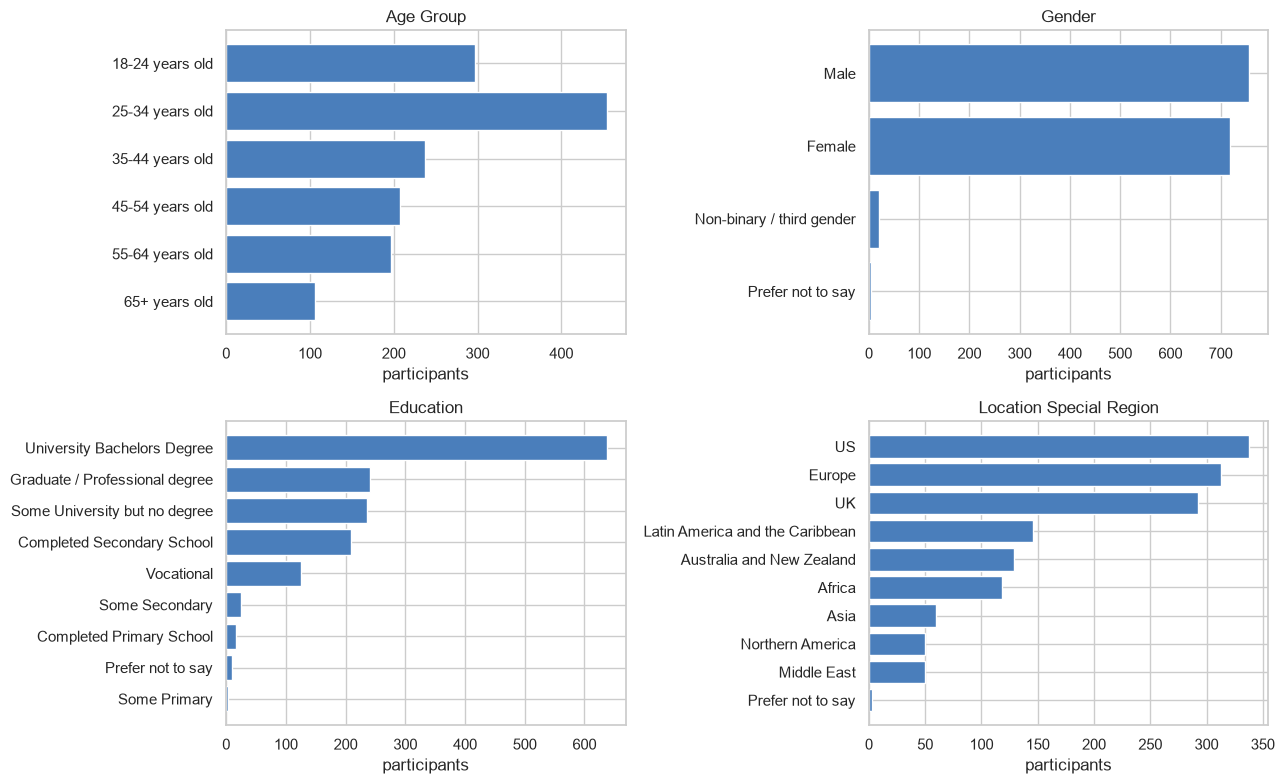

In [23]:
def barh_counts(ax, series, title, top=10):
    counts = series.value_counts()
    ordered = isinstance(series.dtype, pd.CategoricalDtype) and series.cat.ordered
    counts = counts.sort_index() if ordered else counts.head(top)
    labels = [str(i)[:38] for i in counts.index]
    ax.barh(labels[::-1], counts.values[::-1], color="#4a7ebb")
    ax.set_title(title)
    ax.set_xlabel("participants")

demo_cols = ["age_group", "gender", "education", "location_special_region"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), demo_cols):
    barh_counts(ax, survey_clean[col].dropna(), col.replace("_", " ").title())
plt.tight_layout()
plt.show()

### What do conversations look like?

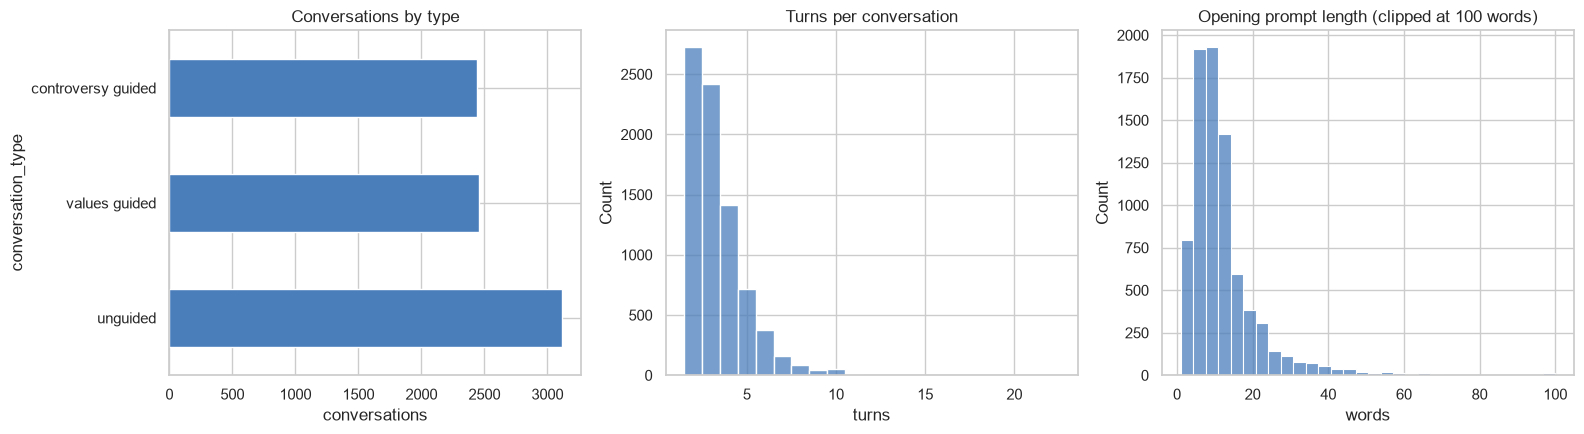

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

conversations_clean["conversation_type"].value_counts().plot.barh(ax=axes[0], color="#4a7ebb")
axes[0].set_title("Conversations by type"); axes[0].set_xlabel("conversations")

sns.histplot(conversations_clean["conversation_turns"], discrete=True, ax=axes[1], color="#4a7ebb")
axes[1].set_title("Turns per conversation"); axes[1].set_xlabel("turns")

sns.histplot(conversations_clean["opening_prompt_words"].clip(upper=100), bins=30, ax=axes[2], color="#4a7ebb")
axes[2].set_title("Opening prompt length (clipped at 100 words)"); axes[2].set_xlabel("words")

plt.tight_layout()
plt.show()

### Which texts are screened out?

The metadata flags decide which responses can be used for the text features. Language matters most for this, as the hedging and refusal word lists are in English.

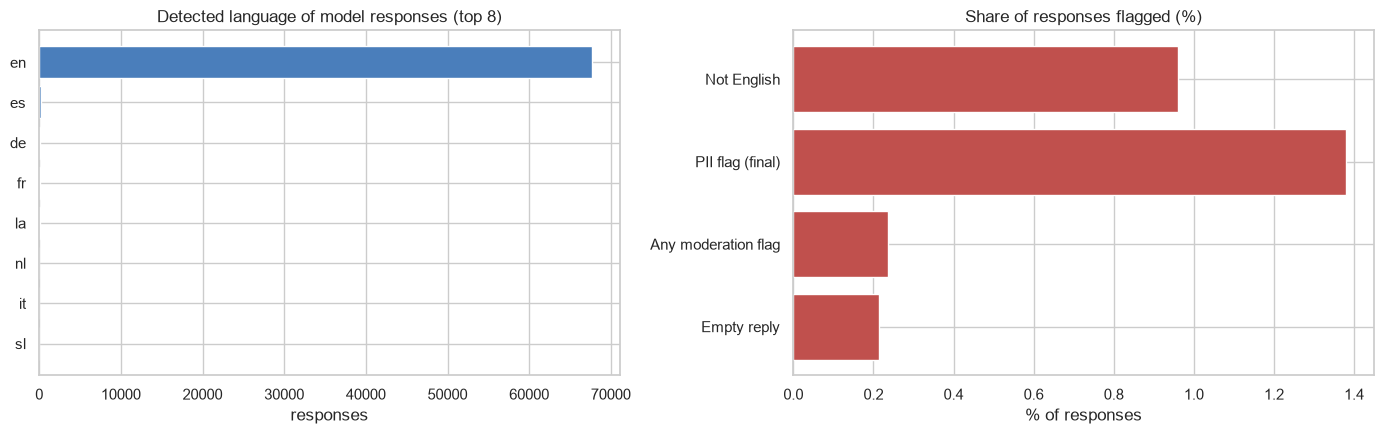

English, non-empty responses: 67568 of 68371 (98.8%)


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

lang_counts = ratings["language_flag"].value_counts().head(8)
axes[0].barh(lang_counts.index[::-1], lang_counts.values[::-1], color="#4a7ebb")
axes[0].set_title("Detected language of model responses (top 8)")
axes[0].set_xlabel("responses")

shares = pd.Series({
    "Not English": 1 - ratings["en_flag"].mean(),
    "PII flag (final)": ratings["pii_flag_final"].mean(),
    "Any moderation flag": ratings["any_moderation_flag"].astype("float").mean(),
    "Empty reply": ratings["is_empty_response"].mean(),}).dropna()
axes[1].barh(shares.index[::-1], 100 * shares.values[::-1], color="#c0504d")
axes[1].set_title("Share of responses flagged (%)")
axes[1].set_xlabel("% of responses")

plt.tight_layout()
plt.show()

#English responses are used for language-feature analysis
ratings_en = ratings[(ratings["en_flag"] == True) & (~ratings["is_empty_response"])]
print(f"English, non-empty responses: {len(ratings_en)} of {len(ratings)} ({len(ratings_en)/len(ratings):.1%})")

### How are responses rated?

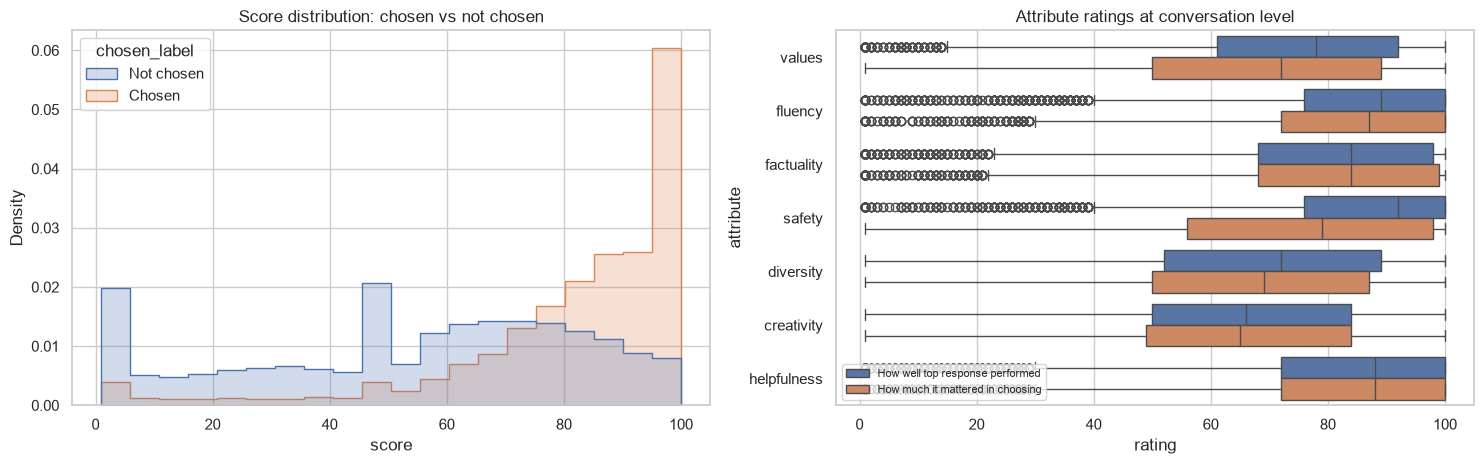

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.histplot(data=ratings, x="score", hue="chosen_label", bins=20, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Score distribution: chosen vs not chosen")

attr_long = pd.concat([
    conversations_clean[perf_cols].melt(var_name="attribute", value_name="rating").assign(kind="How well top response performed"),
    conversations_clean[choice_cols].melt(var_name="attribute", value_name="rating").assign(kind="How much it mattered in choosing"),], ignore_index=True)
attr_long["attribute"] = attr_long["attribute"].str.replace(r"^(perf|choice)_", "", regex=True)
sns.boxplot(data=attr_long, y="attribute", x="rating", hue="kind", ax=axes[1])
axes[1].set_title("Attribute ratings at conversation level")
axes[1].legend(title="", fontsize=8, loc="lower left")

plt.tight_layout()
plt.show()


Ratings range from 1-100, so as I expected, there are clusters around key areas (50 and 100). Shown above (left) is whether chosen responses score higher than unchosen responses overall, but this plot doesn’t compare alternatives within the same turn to confirm a direct preference.

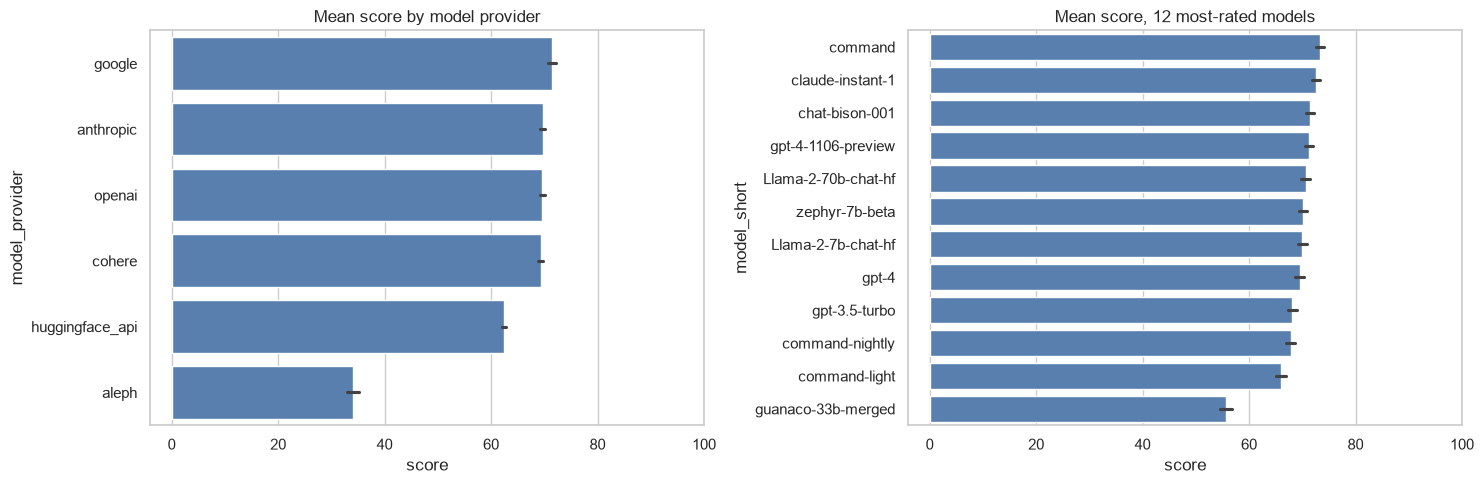

In [27]:
# Ratings by model provider and (most common) model, with approximate 95% intervals
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

prov_order = ratings.groupby("model_provider")["score"].mean().sort_values(ascending=False).index
sns.barplot(data=ratings, y="model_provider", x="score", order=prov_order,
            errorbar=("se", 1.96), color="#4a7ebb", ax=axes[0])
axes[0].set_title("Mean score by model provider")

top_models = ratings["model_short"].value_counts().head(12).index
sub = ratings[ratings["model_short"].isin(top_models)]
mod_order = sub.groupby("model_short")["score"].mean().sort_values(ascending=False).index
sns.barplot(data=sub, y="model_short", x="score", order=mod_order,
            errorbar=("se", 1.96), color="#4a7ebb", ax=axes[1])
axes[1].set_title("Mean score, 12 most-rated models")

for ax in axes:
    ax.set_xlim(ratings["score"].quantile(0.01) - 5, 100)
plt.tight_layout()
plt.show()

`Huggingface_api` is only the host for open models, not their builder, so provider groups mix very different models. Participants also rate only their own conversations, so user and prompt effects are mixed in with model effects (something that also showed up in my 2c).

### Do language features relate to ratings?

Using English, non-empty responses only.

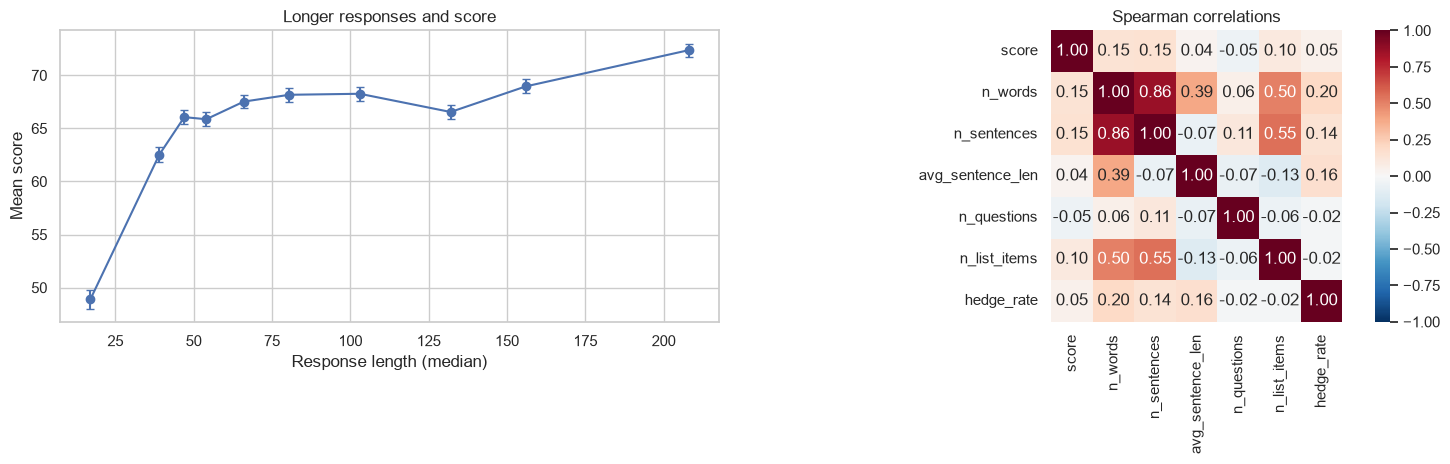

In [28]:
d = ratings_en.dropna(subset=["score", "n_words"]).copy()
d["words_decile"] = pd.qcut(d["n_words"], 10, duplicates="drop")
g = (d.groupby("words_decile", observed=True)
       .agg(median_words=("n_words", "median"), mean_score=("score", "mean"),
            se=("score", "sem"), n=("score", "size")))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].errorbar(g["median_words"], g["mean_score"], yerr=1.96 * g["se"], marker="o", capsize=3)
axes[0].set_xlabel("Response length (median)")
axes[0].set_ylabel("Mean score")
axes[0].set_title("Longer responses and score")

corr = ratings_en[["score"] + feature_cols].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, ax=axes[1])
axes[1].set_title("Spearman correlations")
plt.tight_layout()
plt.show()

Correlation here is used as an indicator only - length, number of sentences and number of list items all rise together, so their separate contributions cannot be read from this chart (which is something that perhaps regression modelling can help with, with all of them included).

### Do people agree on the best response within a turn?

As mentioned before, a look within a turn will be more revealing as to preference. A turn (`interaction_id`) shows several responses: up to four in the first turn, two in later turns. How far apart are their scores, and does the response a person *chose* match the one they scored highest?

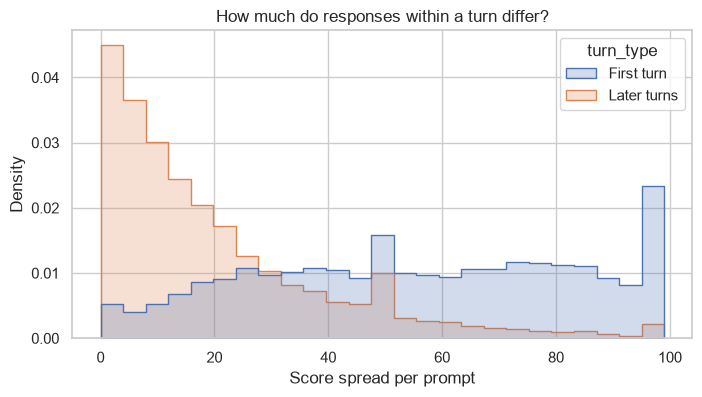

Share of chosen responses that also received the highest score in their turn: 99.5%


In [29]:
inter = (ratings.groupby("interaction_id")
         .agg(turn=("turn", "first"), n_options=("score", "size"),
              score_min=("score", "min"), score_max=("score", "max"),
              n_chosen=("if_chosen", "sum"))
         .reset_index())
inter["score_range"] = inter["score_max"] - inter["score_min"]
inter["turn_type"] = np.where(inter["turn"] == 0, "First turn", "Later turns")

top_in_turn = ratings.groupby("interaction_id")["score"].transform("max")
is_chosen = ratings["if_chosen"] == True
chosen_is_top = (ratings.loc[is_chosen, "score"] == top_in_turn[is_chosen]).mean()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=inter, x="score_range", hue="turn_type", bins=25, stat="density",
             common_norm=False, element="step", ax=ax)
ax.set_xlabel("Score spread per prompt")
ax.set_title("How much do responses within a turn differ?")
plt.show()

print(f"Share of chosen responses that also received the highest score in their turn: {chosen_is_top:.1%}")

Above: It appears there is most variation amongst responses in the first turn, which then converges towards an agreed preference in later turns (likely due to continuing with the preferred choice)

### Stated versus revealed priorities (a preview of candidate question B)

Before rating anything, participants said how important each AI behaviour is to them (`stated_prefs`, 0 to 100).  

After each conversation they said how much each attribute mattered in choosing their top response (`choice_attributes`, 1 to 100). For each attribute, it may be relevant to ask if those who *say* it matters also *act* as if it matters (as according to their ratings)? 

*Note that `personalisation` was only asked in the survey, so it has no matching choice rating.*

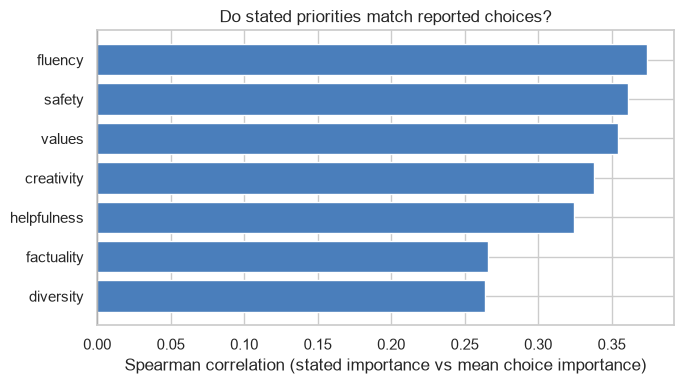

,attribute,n_users,spearman
4,diversity,1381,0.264
2,factuality,1393,0.266
6,helpfulness,1394,0.324
5,creativity,1378,0.338
0,values,1372,0.354
3,safety,1381,0.361
1,fluency,1395,0.374


In [30]:
attrs = [c.replace("choice_", "") for c in choice_cols]
rows = []
for a in attrs:
    s, c = f"stated_prefs_{a}", f"mean_choice_{a}"
    if s in user_level.columns and c in user_level.columns:
        dd = user_level[[s, c]].dropna()
        rows.append({"attribute": a, "n_users": len(dd),
                     "spearman": dd[s].corr(dd[c], method="spearman")})
stated_vs_choice = pd.DataFrame(rows).sort_values("spearman")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(stated_vs_choice["attribute"], stated_vs_choice["spearman"], color="#4a7ebb")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation (stated importance vs mean choice importance)")
ax.set_title("Do stated priorities match reported choices?")
plt.tight_layout()
plt.show()
stated_vs_choice.round(3)

### First look at group differences (Perhaps a foundation for the main research question)

For each group, how strongly does response length correlate with score? If the bars differ significantly, an interesting research question (below) emerges. For this, groups with fewer than 20 participants are left out, because a correlation based on a small group will be unreliable.

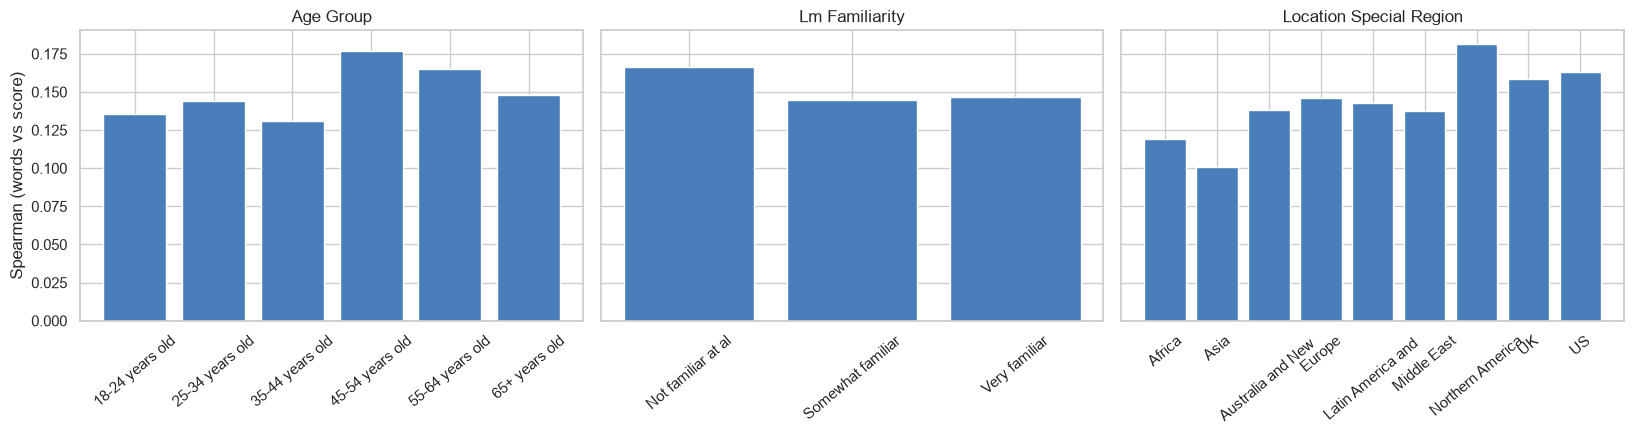

,variable,group,n_users,n_ratings,spearman_words_score
0,age_group,18-24 years old,280,13414,0.135
1,age_group,25-34 years old,426,21066,0.144
2,age_group,35-44 years old,224,11102,0.131
3,age_group,45-54 years old,189,9132,0.177
4,age_group,55-64 years old,181,8503,0.165
5,age_group,65+ years old,95,4351,0.148
0,lm_familiarity,Not familiar at all,144,6458,0.167
1,lm_familiarity,Somewhat familiar,855,42125,0.145
2,lm_familiarity,Very familiar,396,18985,0.147
0,location_special_region,Africa,114,5062,0.119


In [31]:
MIN_USERS = 20
group_vars = [v for v in ["age_group", "lm_familiarity", "location_special_region"] if v in ratings_en.columns]

fig, axes = plt.subplots(1, len(group_vars), figsize=(5.5 * len(group_vars), 4.5), sharey=True)
axes = np.atleast_1d(axes)
tables = []
for ax, var in zip(axes, group_vars):
    rows = []
    for level, dd in ratings_en.dropna(subset=[var, "score", "n_words"]).groupby(var, observed=True):
        if dd["user_id"].nunique() >= MIN_USERS:
            rows.append({"variable": var, "group": str(level), "n_users": dd["user_id"].nunique(),
                         "n_ratings": len(dd),
                         "spearman_words_score": dd["n_words"].corr(dd["score"], method="spearman")})
    t = pd.DataFrame(rows)
    tables.append(t)
    ax.bar(t["group"].str[:18], t["spearman_words_score"], color="#4a7ebb")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(var.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=40)
axes[0].set_ylabel("Spearman (words vs score)")
plt.tight_layout()
plt.show()
pd.concat(tables).round(3)

## 6. Research question and possible paths of analysis



The data support several different projects. Possibilities include:

| # | Candidate question | Data needed | Strength | Main risk |
|---|---|---|---|---|
| A | Which language features of AI responses are associated with higher ratings, and does this differ across user groups? | `model_response` text features, `score`, survey groups | Uses all the tables; links to the stated aims of the notebook | Features are correlated; groups can be small |
| B | Do people's *stated* priorities (`stated_prefs`) match what they report drove their choices (`choice_attributes`), and which responses do they pick? | survey `stated_prefs_*`, `choice_*`, `if_chosen`, response features | Stated vs revealed preference is a clean contrast, and the section 5 preview shows the data exist | Eight stated attributes but seven choice attributes, and the scales differ (0 to 100 vs 1 to 100) |
| C | Do ratings differ by model once user and prompt are accounted for? | `model_name`, `score`, user and conversation ids | Directly useful for AI evaluation | Models are not randomly assigned to users, and a provider such as `huggingface_api` bundles many models |
| D | What do participants say in free-text feedback, and how does it relate to their ratings? | `open_feedback`, `perf_*` ratings | Text analysis opportunity | Feedback is per conversation, so it is a less precise unit than a response |

### Preliminary research question (A)

> **Which linguistic features of AI responses (length, structure, hedging, questions) are associated with higher user ratings, and does that relationship differ across groups of users (age, region, familiarity with language models)?**

Following well from my 2c, this works because it uses every part of the merged data, the language features were prepared from section 3, and the preview chart in section 5 shows that it is feasible with the data available. Option B is a good second study and can reuse the same `user_level` table.

**Hypotheses (to be tested, not assumed):**

1. **H1:** Longer and more structured responses receive higher scores, with decreasing returns beyond a certain length.
2. **H2:** Refusal-like language lowers scores; hedging lowers them less (or even raises them) in `controversy guided` conversations.
3. **H3:** The length-score relationship differs by user group, for example by age group or familiarity with language models.

**Unit of analysis:** one rated response, recorded within a turn, a conversation and/or per user.  
**Outcome:** `score` (1 to 100); secondary outcome `if_chosen` (whether the response was picked).  
**Predictors:** length, sentence length, list items, questions, hedging, refusal-like phrasing (English responses only).  
**Moderators:** age group, region (`location_special_region`), familiarity with language models, conversation type.  
**Controls:** model, opening prompt length, number of turns, whether it was the first turn.

**What this can and cannot show:** 
- Associations between features and ratings in this sample. It cannot show that changing a feature *causes* a higher rating, only that it correlates.
- It cannot be generalised to people outside the participant pool. 
- One consequence for the aims listed at the top of the notebook: because each conversation is rated by a single person, "how much do people agree" cannot be measured directly as inter-rater agreement *within* groups. It can only be approached/inferred by comparing patterns *between groups*.



## 7. Plan for modelling and analysis


- **Main task, regression:** predict `score` (1 to 100) from the response features, and check whether the relationship differs between user groups.
- **Secondary task, classification:** predict whether a response was chosen (`if_chosen`), which is a yes/no outcome.

The aim is to understand *which* features matter, not to get the most accurate predictions, so I will use simple, easy-to-interpret models.

### Data preparation

- Check the 265 turns that have more than one chosen response, and compare results with and without them.
- Use/filter for English, non-empty responses (`ratings_en`) for all language-feature models.
- Log-transform skewed features such as word count, and standardise predictors so coefficients can be compared.
- Do not use `perf_*` and `choice_*` columns as predictors. They are recorded after the rating, so they would leak the answer from training into the test.
- Keep "Prefer not to say" as its own category, and combine very small demographic groups.
- Check unusually long or short responses, and scores clustered near 50 and 100.
- Keep responses flagged for PII or moderation, but censor or avoid text when used for reporting.

### Descriptive analysis

- Summary tables of group sizes, average scores and confidence intervals.
- Compare groups using effect sizes, not only p-values.
- Simple tests such as Kruskal-Wallis or Mann-Whitney, adjusting for multiple comparisons.

### Modelling

1. **Baselines:** predict the overall mean score, and a model using only which AI model replied. These show how much the language features add.
2. **Linear regression:** score predicted from the language features plus controls (model, prompt length, first turn). Adding group x feature interaction terms tests whether the effects differ between groups (H3).
3. **Ridge and lasso regression:** length, sentence count and list items are strongly related, so these methods give more stable results and show which features matter most.
4. **Logistic regression:** predict whether a response was chosen (`if_chosen`). I would also compare responses within the same turn, so the prompt and the person stay the same.
5. **Optional NLP:** use TF-IDF or sentence embeddings instead of hand-made features.

### Avoiding over- and under-fitting

- **Under-fitting:** start from the simple baselines and check whether adding features or interactions improves results on unseen data. Residual plots can show if a pattern is being missed.
- **Over-fitting:** split the data into training and test sets **by user**, so one person's ratings never appear in both. Keep the test set untouched until the end, and use cross-validation (also by user) on the training set to choose settings such as regularisation strength.
- Only include the interactions planned in H1 to H3, and adjust for multiple comparisons.

### Evaluation and choosing between models

- **Regression:** R-squared is likely to be low, because ratings depend on much more than style, and I will report this honestly.
- **Classification:** accuracy and ROC AUC, compared with chance (50% for two options, 25% for four), plus whether the model picks the response the person chose within each turn.
- **Choosing a model:** I'd prefer the simplest model that performs about as well as the best one, because it is easier to explain.
- **Uncertainty:** report confidence intervals, and check that the main findings hold on the balanced subset.

### Validation and considerations

- Scores run from 1 to 100, so consider whether another approach, such as using `if_chosen` alone, is more suitable.
- Report the number of participants in each group.
- Participants chose to take part and reported information about themselves, so findings may not apply to everyone. This limits generalisability.